In [ ]:
# --- project bootstrap: run from anywhere, keeps data/ and figures/ paths working ---
import os, sys
from pathlib import Path
_here = Path.cwd()
if _here.name == "notebooks":          # notebook lives in notebooks/, project root is one level up
    os.chdir(_here.parent)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))  # makes `from coherence import ...` available
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("project root:", ROOT)


In [1]:
# Cell 1 — imports + both T2 functions (self-contained)
import scqubits as scq, numpy as np, pandas as pd, matplotlib.pyplot as plt
scq.settings.T1_DEFAULT_WARNING = False
def safe(fn, **kw):
    try: return fn(**kw)
    except Exception: return np.inf

def transmon_T2(EJ, EC, ng=0.0, ncut=30, Q_cap=1e6, A_ng=1e-4, A_cc=1e-7):
    tm = scq.Transmon(EJ=EJ, EC=EC, ng=ng, ncut=ncut)
    T1  = safe(tm.t1_capacitive, i=1, j=0, Q_cap=Q_cap)
    Tng = safe(tm.tphi_1_over_f_ng, A_noise=A_ng, i=0, j=1)
    Tcc = safe(tm.tphi_1_over_f_cc, A_noise=A_cc, i=0, j=1)
    return (1/(1/(2*T1)+1/Tng+1/Tcc))*1e-3

def fluxonium_T2(EJ=8.9, EC=2.5, EL=0.5, flux=0.5, cutoff=110, Q_cap=1e6, A_flux=1e-6, A_cc=1e-7):
    fx = scq.Fluxonium(EJ=EJ, EC=EC, EL=EL, flux=flux, cutoff=cutoff)
    T1 = 1/(1/safe(fx.t1_capacitive, i=1, j=0, Q_cap=Q_cap)
            + 1/safe(fx.t1_quasiparticle_tunneling, i=1, j=0))
    Tf  = safe(fx.tphi_1_over_f_flux, A_noise=A_flux, i=0, j=1)
    Tcc = safe(fx.tphi_1_over_f_cc, A_noise=A_cc, i=0, j=1)
    return (1/(1/(2*T1)+1/Tf+1/Tcc))*1e-3

In [2]:
# Cell 2 — build the architecture comparison table from your saved data
dft = pd.read_csv('data/transmon_full_sweep.csv')
tmon_best = dft[dft.EJ_EC >= 20].T2_us.max()
dfx = pd.read_csv('data/fluxonium_design_sweep.csv')
flux_best = dfx.T2_us.max()

ng = np.linspace(0, 0.5, 101);   tmon_bias = [transmon_T2(50, 1.0, ng=n) for n in ng]
fl = np.linspace(0.45, 0.5, 101); flux_bias = [fluxonium_T2(flux=f) for f in fl]
tmon_factor = max(tmon_bias)/min(tmon_bias)
flux_factor = max(flux_bias)/min(flux_bias)

table = pd.DataFrame({
 'Metric': ['Best T2 (real regime)', 'Bias-knob sensitivity (T2 max/min)',
            'Dominant noise channel', 'Sweet-spot scaling', 'Practical character'],
 'Transmon': [f'{tmon_best:.0f} us', f'{tmon_factor:.2f}x',
              'dielectric relaxation', 'flat (no sharp knob)', 'simple, forgiving'],
 'Fluxonium': [f'{flux_best:.0f} us', f'{flux_factor:.0f}x',
               'flux noise off spot; relaxation at 0.5', 'T2 ~ detuning^-0.68',
               'delicate, must hold flux=0.5'],
})
table.to_csv('data/architecture_comparison.csv', index=False)
print(table.to_string(index=False))

                            Metric              Transmon                              Fluxonium
             Best T2 (real regime)                187 us                                5578 us
Bias-knob sensitivity (T2 max/min)                 1.01x                                   528x
            Dominant noise channel dielectric relaxation flux noise off spot; relaxation at 0.5
                Sweet-spot scaling  flat (no sharp knob)                    T2 ~ detuning^-0.68
               Practical character     simple, forgiving           delicate, must hold flux=0.5


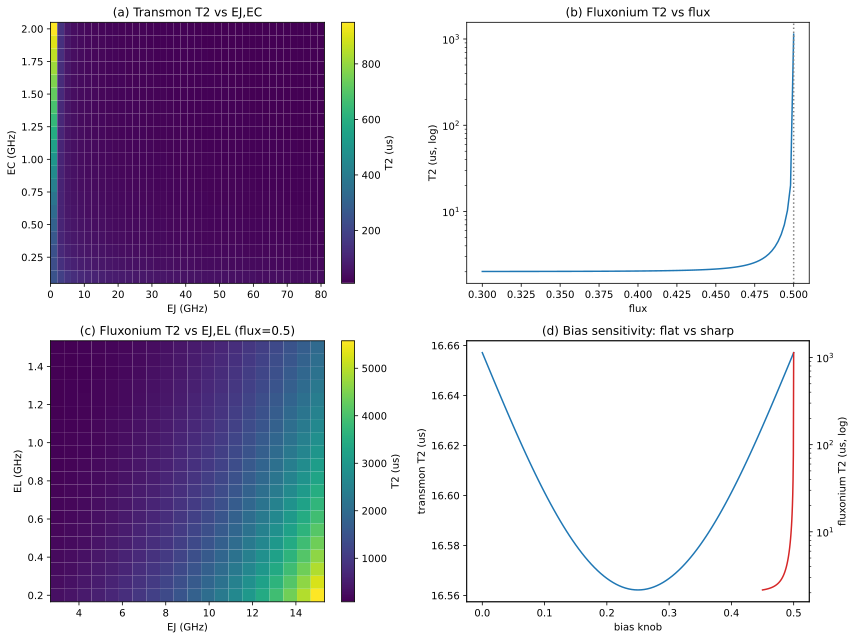

In [3]:
# Cell 3 — 4-panel summary figure, rebuilt from saved CSVs
dfxs = pd.read_csv('data/fluxonium_flux_sweep.csv')
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

# (a) transmon T2 map
p = dft.pivot(index='EC', columns='EJ', values='T2_us')
im = ax[0,0].pcolormesh(p.columns, p.index, p.values, shading='auto')
fig.colorbar(im, ax=ax[0,0], label='T2 (us)')
ax[0,0].set(title='(a) Transmon T2 vs EJ,EC', xlabel='EJ (GHz)', ylabel='EC (GHz)')

# (b) fluxonium flux falloff
ax[0,1].semilogy(dfxs.flux, dfxs.T2_us)
ax[0,1].axvline(0.5, color='gray', ls=':')
ax[0,1].set(title='(b) Fluxonium T2 vs flux', xlabel='flux', ylabel='T2 (us, log)')

# (c) fluxonium design map
pf = dfx.pivot(index='EL', columns='EJ', values='T2_us')
im = ax[1,0].pcolormesh(pf.columns, pf.index, pf.values, shading='auto')
fig.colorbar(im, ax=ax[1,0], label='T2 (us)')
ax[1,0].set(title='(c) Fluxonium T2 vs EJ,EL (flux=0.5)', xlabel='EJ (GHz)', ylabel='EL (GHz)')

# (d) bias sensitivity comparison
ax[1,1].plot(ng, tmon_bias, label='transmon (vs ng)')
axr = ax[1,1].twinx()
axr.semilogy(fl, flux_bias, color='tab:red', label='fluxonium (vs flux)')
ax[1,1].set(title='(d) Bias sensitivity: flat vs sharp', xlabel='bias knob')
ax[1,1].set_ylabel('transmon T2 (us)'); axr.set_ylabel('fluxonium T2 (us, log)')

plt.tight_layout()
plt.savefig('figures/summary_figure.png', dpi=150, bbox_inches='tight')
plt.show()